# Fake News Detection — Model Development and Evaluation

This notebook develops and evaluates machine learning models for binary fake-news classification.

The modelling workflow builds directly on the cleaned and validated dataset produced in Notebook 1 and the exploratory text analysis completed in Notebook 2.

The main modelling objective is to classify an article as either:

- **Fake (0)**
- **True (1)**

The primary input is the combined article title and body text. Metadata such as subject and date is retained for analysis but is not used as a primary predictive feature.

The notebook covers:

- Train-validation splitting
- TF-IDF feature extraction
- Baseline NLP models
- Model comparison
- Cross-validation
- Hyperparameter tuning
- Final model selection
- Validation-set evaluation
- Confusion matrix and classification report
- ROC-AUC analysis
- Error analysis
- Model persistence
- Reproducibility checks

## Modelling Objective

The goal is not simply to maximise accuracy.

Because this is a binary text-classification problem, the evaluation focuses on:

- Precision
- Recall
- F1-score
- Accuracy
- ROC-AUC
- Confusion matrix

F1-score is used as the primary comparison metric because it balances precision and recall.

The validation set is kept separate from model fitting and hyperparameter selection so that the final reported validation performance remains an independent estimate of generalisation within this dataset.

In [1]:
from pathlib import Path
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

## Project Paths

The notebook uses the same project structure established in Notebook 1 and Notebook 2.

The processed modelling dataset is loaded instead of rebuilding the cleaning workflow here. This keeps each notebook focused on one stage of the project while maintaining a consistent pipeline.

In [2]:
def find_project_root(start_path=None):
    start_path = Path(start_path or Path.cwd()).resolve()

    for path in [start_path] + list(start_path.parents):
        if (path / "data").exists() and (path / "notebooks").exists():
            return path

    raise FileNotFoundError(
        "Could not locate the Fake-News-Detection project root."
    )


PROJECT_ROOT = find_project_root()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    PROCESSED_DATA_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

PROCESSED_DATA_PATH = (
    PROCESSED_DATA_DIR / "news_modeling_data.csv"
)

print("Project root:")
print(PROJECT_ROOT)

Project root:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection


## Load the Cleaned Modelling Dataset

Notebook 1 created `news_modeling_data.csv` after handling:

- label creation
- missing and empty text
- duplicate content
- conflicting labels
- text construction
- final schema validation

Notebook 3 therefore starts from this validated modelling dataset.

In [3]:
if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {PROCESSED_DATA_PATH}"
    )

modeling_df = pd.read_csv(PROCESSED_DATA_PATH)

print("Loaded dataset successfully.")
print(f"Shape: {modeling_df.shape}")

Loaded dataset successfully.
Shape: (39100, 7)


In [4]:
REQUIRED_COLUMNS = [
    "title",
    "text",
    "subject",
    "date",
    "label",
    "label_name",
    "model_text",
]

missing_columns = [
    column
    for column in REQUIRED_COLUMNS
    if column not in modeling_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")
print(REQUIRED_COLUMNS)

All required columns are present.
['title', 'text', 'subject', 'date', 'label', 'label_name', 'model_text']


## Dataset Sanity Checks

Before training any model, the dataset is checked again.

These checks are intentionally lightweight and defensive. They ensure that the modelling notebook does not silently continue with invalid labels or empty model text.

In [5]:
assert modeling_df["label"].isin([0, 1]).all(), (
    "Labels must contain only 0 and 1."
)

assert modeling_df["label_name"].isin(["Fake", "True"]).all(), (
    "Unexpected label names detected."
)

assert modeling_df["model_text"].notna().all(), (
    "model_text contains missing values."
)

assert (
    modeling_df["model_text"].astype(str).str.strip().str.len() > 0
).all(), "model_text contains empty documents."

assert modeling_df["label"].nunique() == 2, (
    "Both classes must be present."
)

print("All modelling sanity checks passed.")

All modelling sanity checks passed.


## Target Distribution

The target distribution is inspected once more before splitting the data.

A stratified split will be used so that the proportion of Fake and True articles remains approximately consistent between the training and validation sets.

In [6]:
class_distribution = (
    modeling_df["label_name"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="count")
)

class_distribution["percentage"] = (
    class_distribution["count"]
    / class_distribution["count"].sum()
    * 100
)

class_distribution

,label,count,percentage
0,True,21195,54.207161
1,Fake,17905,45.792839


## Define Features and Target

The primary predictive text is `model_text`, created in Notebook 1 from:

`title + text`

The metadata columns `subject` and `date` are intentionally excluded from the primary classifier.

This keeps the main model focused on linguistic information rather than potentially dataset-specific metadata patterns.

In [7]:
X = modeling_df["model_text"].astype(str)
y = modeling_df["label"].astype(int)

print("Feature variable:", X.name)
print("Target variable:", y.name)
print("Number of documents:", len(X))
print("Number of labels:", len(y))

Feature variable: model_text
Target variable: label
Number of documents: 39100
Number of labels: 39100


## Train-Validation Split

The data is split before TF-IDF fitting.

This order is important:

1. Split the documents.
2. Fit TF-IDF only on training text.
3. Transform validation text using the training vocabulary and IDF weights.
4. Train models using the transformed training representation.
5. Evaluate on unseen validation data.

This prevents information from the validation set from influencing the learned vocabulary or IDF statistics.

In [8]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training documents:", len(X_train))
print("Validation documents:", len(X_valid))

Training documents: 31280
Validation documents: 7820


In [9]:
split_summary = pd.DataFrame({
    "Dataset": ["Full", "Training", "Validation"],
    "Documents": [
        len(X),
        len(X_train),
        len(X_valid),
    ],
})

split_summary

,Dataset,Documents
0,Full,39100
1,Training,31280
2,Validation,7820


In [10]:
split_class_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_valid.value_counts(normalize=True),
}).fillna(0)

split_class_summary.index = split_class_summary.index.map({
    0: "Fake",
    1: "True",
})

split_class_summary["Difference_pp"] = (
    (split_class_summary["Training"]
     - split_class_summary["Validation"])
    * 100
)

split_class_summary

,Training,Validation,Difference_pp
label,,,
True,0.542072,0.542072,0.0
Fake,0.457928,0.457928,0.0


## TF-IDF Representation

Term Frequency-Inverse Document Frequency (TF-IDF) converts text into numerical features.

The representation captures how important a word or n-gram is within a document relative to the overall training corpus.

Both unigrams and bigrams are used because individual words can be informative, while short word combinations can capture additional context.

The vectorizer is fitted only on the training portion through the modelling pipeline.

In [11]:
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    max_features=100000,
)

print(tfidf)

TfidfVectorizer(max_df=0.95, max_features=100000, min_df=2, ngram_range=(1, 2),
                stop_words='english', strip_accents='unicode',
                sublinear_tf=True)


## Model Selection Strategy

Three classical machine-learning models are compared:

1. **Logistic Regression**
2. **Linear Support Vector Machine**
3. **Multinomial Naive Bayes**

These models are well suited to high-dimensional sparse TF-IDF text representations.

The comparison is deliberately model-based rather than relying on a single algorithm.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "Linear SVM": LinearSVC(
        random_state=RANDOM_STATE,
    ),
    "Multinomial Naive Bayes": MultinomialNB(),
}

print("Models to compare:")
for name in models:
    print("-", name)

Models to compare:
- Logistic Regression
- Linear SVM
- Multinomial Naive Bayes


## Build Leakage-Safe Pipelines

Each model is placed after the TF-IDF vectorizer inside a scikit-learn Pipeline.

This means that when cross-validation is performed, TF-IDF is refitted separately inside each training fold rather than being calculated once using the complete dataset.

This is an important part of keeping the evaluation leakage-safe.

In [13]:
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
            max_features=100000,
        )),
        ("model", model),
    ])

print("Pipelines created:")
for name in pipelines:
    print("-", name)

Pipelines created:
- Logistic Regression
- Linear SVM
- Multinomial Naive Bayes


## Baseline Model Training

Each baseline pipeline is trained on the training set only.

The validation set remains untouched during this stage.

The first comparison uses the default model configurations with sensible iteration settings.

In [14]:
baseline_results = []
baseline_predictions = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_valid)
    baseline_predictions[name] = predictions

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(
            y_valid,
            predictions,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_valid,
            predictions,
            zero_division=0,
        ),
        "F1": f1_score(
            y_valid,
            predictions,
            zero_division=0,
        ),
    })

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

baseline_results_df

,Model,Accuracy,Precision,Recall,F1
0,Linear SVM,0.996292,0.994828,0.998349,0.996585
1,Logistic Regression,0.989642,0.985748,0.995282,0.990492
2,Multinomial Naive Bayes,0.960486,0.961701,0.965558,0.963626


## Baseline Model Comparison

The baseline results provide an initial reference point.

F1-score is used as the main comparison metric because a useful fake-news classifier should balance the ability to identify positive cases with the reliability of those predictions.

Accuracy is retained as a supporting metric rather than being used alone. 

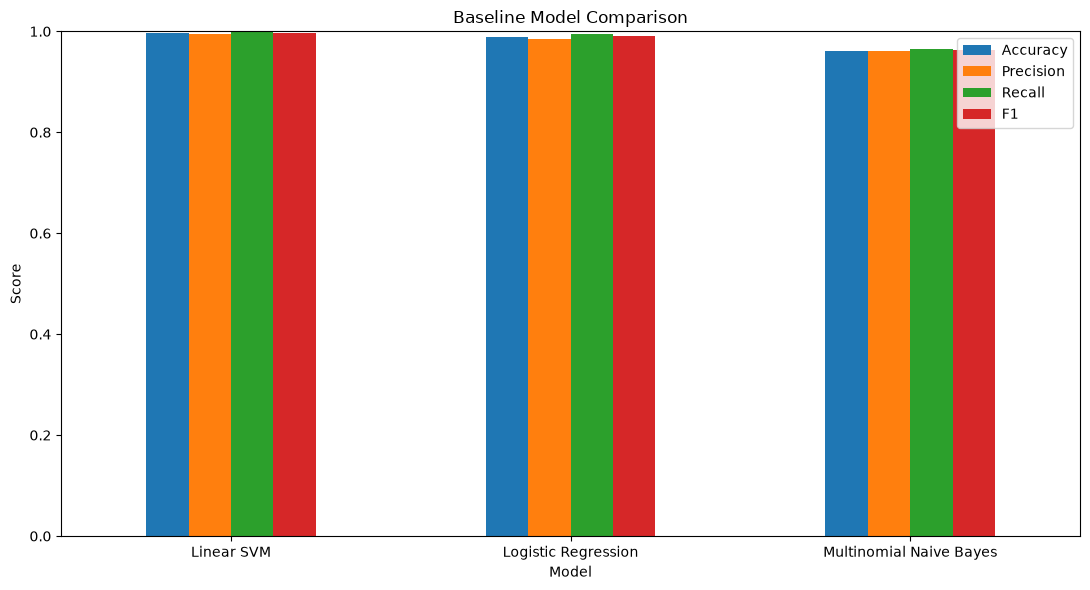

In [15]:
baseline_plot_df = baseline_results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
]

baseline_plot_df.plot(
    kind="bar",
    figsize=(11, 6),
)

plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

baseline_comparison_path = (
    FIGURES_DIR / "baseline_model_comparison.png"
)

plt.savefig(
    baseline_comparison_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## Cross-Validation Strategy

A single validation split is useful for final evaluation, but model development benefits from a more stable estimate.

Five-fold stratified cross-validation is therefore performed on the training set.

The validation set created earlier is still kept aside.

Each fold independently fits the TF-IDF representation and the classifier.

In [16]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [17]:
cv_results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV Precision Mean": scores["test_precision"].mean(),
        "CV Recall Mean": scores["test_recall"].mean(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("CV F1 Mean", ascending=False)
    .reset_index(drop=True)
)

cv_results_df

,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV F1 Std
0,Linear SVM,0.995364,0.001506,0.993774,0.997700,0.995733,0.001386
1,Logistic Regression,0.988491,0.001602,0.983852,0.995105,0.989445,0.001463
2,Multinomial Naive Bayes,0.959974,0.001370,0.961453,0.964850,0.963146,0.001249


## Cross-Validation Interpretation

Cross-validation is used here as a model-development tool.

The mean F1-score shows the typical performance across the five training folds, while the standard deviation indicates how much the score changes between folds.

The final validation set is not used during this comparison.

In [18]:
cv_results_path = (
    REPORTS_DIR / "cross_validation_results.csv"
)

cv_results_df.to_csv(
    cv_results_path,
    index=False,
)

print(f"Saved: {cv_results_path}")

Saved: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\cross_validation_results.csv


## Hyperparameter Tuning

The strongest classical models are tuned using GridSearchCV.

The search is performed only on the training set.

The TF-IDF vectorizer remains inside the pipeline, so every cross-validation fold learns its own vocabulary and IDF statistics.

F1-score is used as the tuning objective.

In [19]:
logistic_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        max_features=100000,
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    )),
])

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        max_features=100000,
    )),
    ("model", LinearSVC(
        random_state=RANDOM_STATE,
    )),
])

print("Tuning pipelines created.")

Tuning pipelines created.


## Logistic Regression Search Space

The search varies both the regularisation strength and the TF-IDF configuration.

This allows the model-development stage to test whether a different text representation or regularisation setting improves generalisation.

In [20]:
logistic_param_grid = {
    "tfidf__ngram_range": [
        (1, 1),
        (1, 2),
    ],
    "tfidf__min_df": [
        2,
        5,
    ],
    "model__C": [
        0.5,
        1.0,
        2.0,
    ],
    "model__class_weight": [
        None,
        "balanced",
    ],
}

print("Logistic Regression parameter combinations:")
print(
    np.prod([
        len(values)
        for values in logistic_param_grid.values()
    ])
)

Logistic Regression parameter combinations:
24


## Run Logistic Regression Grid Search

In [21]:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression F1:")
print(logistic_grid.best_score_)

print("\nBest parameters:")
print(logistic_grid.best_params_)

Best Logistic Regression F1:
0.9915330104110364

Best parameters:
{'model__C': 2.0, 'model__class_weight': 'balanced', 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 1)}


 ## Linear SVM Search Space

Linear SVM is often effective for sparse, high-dimensional text features.

The search therefore focuses on the regularisation parameter while also checking a small number of TF-IDF configurations.

In [22]:
svm_param_grid = {
    "tfidf__ngram_range": [
        (1, 1),
        (1, 2),
    ],
    "tfidf__min_df": [
        2,
        5,
    ],
    "model__C": [
        0.5,
        1.0,
        2.0,
    ],
    "model__class_weight": [
        None,
        "balanced",
    ],
}

print("Linear SVM parameter combinations:")
print(
    np.prod([
        len(values)
        for values in svm_param_grid.values()
    ])
)

Linear SVM parameter combinations:
24


## Run Linear SVM Grid Search

In [23]:
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

svm_grid.fit(X_train, y_train)

print("Best Linear SVM F1:")
print(svm_grid.best_score_)

print("\nBest parameters:")
print(svm_grid.best_params_)

Best Linear SVM F1:
0.9961141920581362

Best parameters:
{'model__C': 2.0, 'model__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


## Compare Tuned Models

The tuned models are compared using their cross-validation F1-score.

The Naive Bayes baseline remains part of the comparison, while the tuned Logistic Regression and Linear SVM models are evaluated using their best cross-validation scores.

This comparison is used to determine which candidate should be carried forward for final validation.

In [24]:
tuned_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (Tuned)",
        "CV F1 Mean": logistic_grid.best_score_,
        "Best Parameters": str(logistic_grid.best_params_),
    },
    {
        "Model": "Linear SVM (Tuned)",
        "CV F1 Mean": svm_grid.best_score_,
        "Best Parameters": str(svm_grid.best_params_),
    },
])

tuned_comparison

,Model,CV F1 Mean,Best Parameters
0,Logistic Regression (Tuned),0.991533,"{'model__C': 2.0, 'model__class_weight': 'balanced', 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 1)}"
1,Linear SVM (Tuned),0.996114,"{'model__C': 2.0, 'model__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}"


In [25]:
candidate_scores = pd.DataFrame([
    {
        "Model": "Logistic Regression (Tuned)",
        "CV F1 Mean": logistic_grid.best_score_,
    },
    {
        "Model": "Linear SVM (Tuned)",
        "CV F1 Mean": svm_grid.best_score_,
    },
])

candidate_scores = candidate_scores.sort_values(
    "CV F1 Mean",
    ascending=False,
).reset_index(drop=True)

candidate_scores

,Model,CV F1 Mean
0,Linear SVM (Tuned),0.996114
1,Logistic Regression (Tuned),0.991533


## Select the Final Candidate

The model with the strongest cross-validation F1-score is selected for final validation.

This selection is based on the training data and its internal cross-validation results.

The held-out validation set is evaluated only after this decision has been made.

In [26]:
if logistic_grid.best_score_ >= svm_grid.best_score_:
    final_model = logistic_grid.best_estimator_
    final_model_name = "Logistic Regression (Tuned)"
    final_cv_f1 = logistic_grid.best_score_
    final_best_params = logistic_grid.best_params_
else:
    final_model = svm_grid.best_estimator_
    final_model_name = "Linear SVM (Tuned)"
    final_cv_f1 = svm_grid.best_score_
    final_best_params = svm_grid.best_params_

print("Selected final candidate:")
print(final_model_name)

print("\nCross-validation F1:")
print(round(final_cv_f1, 4))

print("\nBest parameters:")
print(final_best_params)

Selected final candidate:
Linear SVM (Tuned)

Cross-validation F1:
0.9961

Best parameters:
{'model__C': 2.0, 'model__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


## Final Validation Evaluation

The final candidate is now evaluated on the held-out validation set.

This is the first point in the notebook where the selected model is assessed on documents that were not used during model selection or hyperparameter tuning.

The following metrics are reported:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC where a continuous decision score is available

In [27]:
final_predictions = final_model.predict(X_valid)

final_accuracy = accuracy_score(
    y_valid,
    final_predictions,
)

final_precision = precision_score(
    y_valid,
    final_predictions,
    zero_division=0,
)

final_recall = recall_score(
    y_valid,
    final_predictions,
    zero_division=0,
)

final_f1 = f1_score(
    y_valid,
    final_predictions,
    zero_division=0,
)

print("Final Model:", final_model_name)
print("-" * 50)
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1-score : {final_f1:.4f}")

Final Model: Linear SVM (Tuned)
--------------------------------------------------
Accuracy : 0.9964
Precision: 0.9951
Recall   : 0.9983
F1-score : 0.9967


## Classification Report

The classification report provides class-level precision, recall and F1-score.

This is useful because an overall F1-score can hide differences between the Fake and True classes.

In [28]:
classification_report_text = classification_report(
    y_valid,
    final_predictions,
    target_names=["Fake", "True"],
    zero_division=0,
)

print(classification_report_text)

              precision    recall  f1-score   support

        Fake       1.00      0.99      1.00      3581
        True       1.00      1.00      1.00      4239

    accuracy                           1.00      7820
   macro avg       1.00      1.00      1.00      7820
weighted avg       1.00      1.00      1.00      7820



## Confusion Matrix

The confusion matrix shows how many validation articles were:

- correctly classified as Fake
- incorrectly classified as True
- incorrectly classified as Fake
- correctly classified as True

This provides a more concrete view of the types of classification errors made by the model.

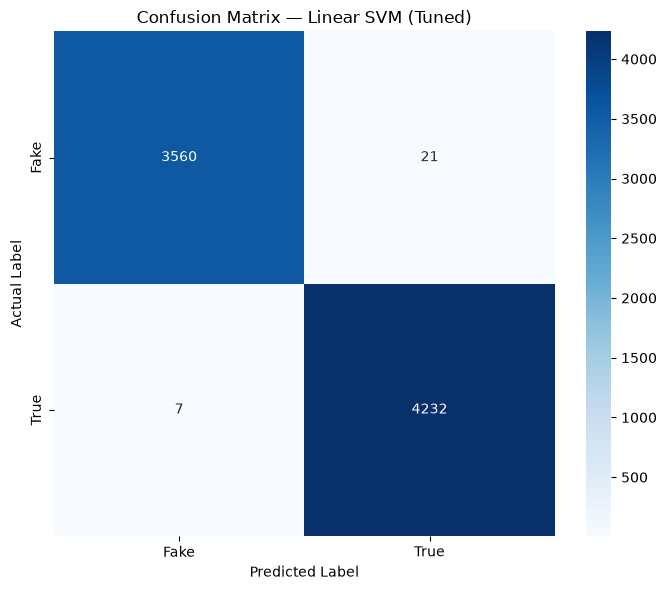

In [29]:
cm = confusion_matrix(
    y_valid,
    final_predictions,
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "True"],
    yticklabels=["Fake", "True"],
)

plt.title(f"Confusion Matrix — {final_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

confusion_matrix_path = (
    FIGURES_DIR / "final_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## ROC-AUC Evaluation

ROC-AUC measures how well the model separates the two classes across different decision thresholds.

For Logistic Regression, probability estimates are available.

For Linear SVM, the decision function is used instead.

ROC-AUC is treated as a supporting metric rather than the sole model-selection criterion.

In [30]:
if hasattr(final_model, "predict_proba"):
    validation_scores = final_model.predict_proba(X_valid)[:, 1]
elif hasattr(final_model, "decision_function"):
    validation_scores = final_model.decision_function(X_valid)
else:
    validation_scores = None

if validation_scores is not None:
    final_roc_auc = roc_auc_score(
        y_valid,
        validation_scores,
    )

    print(f"Validation ROC-AUC: {final_roc_auc:.4f}")
else:
    final_roc_auc = np.nan
    print("ROC-AUC could not be calculated.")

Validation ROC-AUC: 0.9998


## ROC Curve

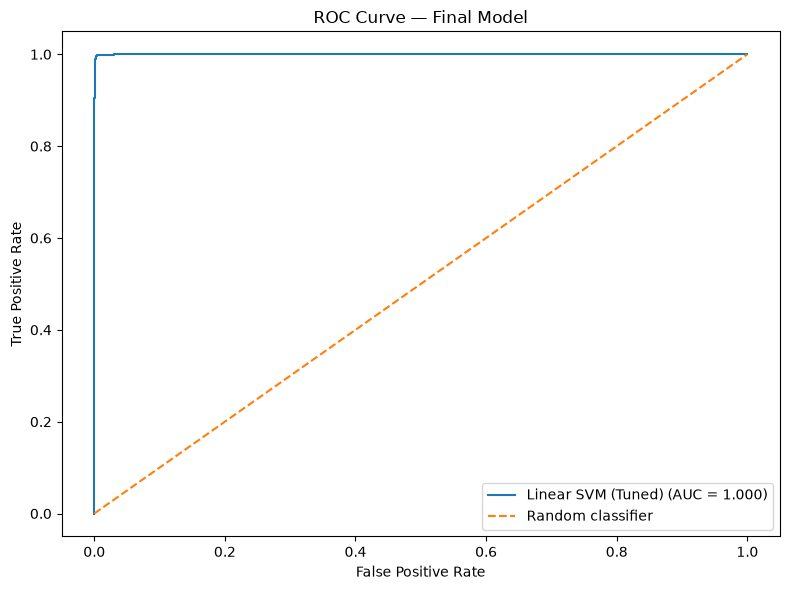

In [31]:
if validation_scores is not None:
    fpr, tpr, thresholds = roc_curve(
        y_valid,
        validation_scores,
    )

    plt.figure(figsize=(8, 6))

    plt.plot(
        fpr,
        tpr,
        label=f"{final_model_name} (AUC = {final_roc_auc:.3f})",
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random classifier",
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — Final Model")
    plt.legend()
    plt.tight_layout()

    roc_curve_path = (
        FIGURES_DIR / "final_roc_curve.png"
    )

    plt.savefig(
        roc_curve_path,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

## Validation Error Analysis

Model evaluation should not end with a single score.

Incorrect predictions are inspected to understand where the classifier struggles.

The review table contains:

- original title
- true label
- predicted label
- model confidence/decision score when available
- article text

This creates a foundation for understanding difficult or ambiguous examples.

In [32]:
error_analysis_df = modeling_df.loc[
    X_valid.index,
    [
        "title",
        "text",
        "subject",
        "date",
        "label",
        "label_name",
    ],
].copy()

error_analysis_df["Predicted_Label"] = final_predictions

error_analysis_df["Predicted_Label_Name"] = (
    error_analysis_df["Predicted_Label"]
    .map({
        0: "Fake",
        1: "True",
    })
)

if validation_scores is not None:
    error_analysis_df["Decision_Score"] = validation_scores

error_analysis_df["Correct"] = (
    error_analysis_df["label"]
    == error_analysis_df["Predicted_Label"]
)

misclassified_df = (
    error_analysis_df[
        ~error_analysis_df["Correct"]
    ]
    .copy()
)

print("Validation errors:", len(misclassified_df))
print("Validation examples:", len(error_analysis_df))

Validation errors: 28
Validation examples: 7820


## Inspect Misclassified Articles

The first examples are displayed for qualitative inspection.

Misclassification does not necessarily mean that an article is factually ambiguous. The model is learning patterns from the dataset's provided labels, so difficult examples can reveal limitations of the dataset, writing style, vocabulary overlap, or model representation.

In [33]:
misclassified_preview = misclassified_df[
    [
        "title",
        "label_name",
        "Predicted_Label_Name",
        "subject",
        "Decision_Score",
    ]
].head(20)

misclassified_preview

,title,label_name,Predicted_Label_Name,subject,Decision_Score
14369,INVASION OF AMERICA: POSSIBILITY OF A TRUMP WALL Has Illegals Racing To Across The Border In Record Numbers,Fake,True,politics,0.114600
14941,BREAKING: US Appeals Court Deals Obama’s Executive Amnesty Huge Blow,Fake,True,politics,0.785646
16243,Putin Declares Syria A “No Fly Zone”…While Obama Is Laser Focused On Gun Control,Fake,True,Government News,0.018809
15331,FED GOV FINES ILLINOIS COMPANY $1.8 MILLION FOR EXPOSING MEXICAN WORKERS TO DANGEROUS SUBSTANCE,Fake,True,politics,0.168519
25782,Commentary: Manic or evasive - these veep guys sure don’t feel like leaders,True,Fake,politicsNews,-0.259228
1679,Court Slams Down Trump’s Order Blocking Funding To Sanctuary Cities,Fake,True,News,0.039853
15707,U.S. APOLOGIZES FOR HUMAN RIGHTS VIOLATIONS AT U.N. REVIEW TO COUNTRIES WITH WORSE HUMAN RIGHTS VIOLATIONS,Fake,True,politics,0.345675
11695,BREAKING: Activist Appeals Court Rules Against Trump…Trump Comes Out Swinging…Tweets Awesome Reply,Fake,True,politics,0.395298
27474,Commentary: Party leaders often disliked their nominee. It’s the public vitriol that’s new.,True,Fake,politicsNews,-0.387667
15850,BREAKING: IRAN THROWS DOWN ULTIMATUM: …Your Move Barry,Fake,True,politics,0.776659


## Validation Error Summary

The error rate is calculated separately from the main performance metrics.

This makes it easier to understand the practical number of validation examples that the final model classified incorrectly.

In [34]:
error_summary = pd.DataFrame({
    "Metric": [
        "Validation examples",
        "Correct predictions",
        "Incorrect predictions",
        "Error rate",
    ],
    "Value": [
        len(error_analysis_df),
        int(error_analysis_df["Correct"].sum()),
        int((~error_analysis_df["Correct"]).sum()),
        1 - final_accuracy,
    ],
})

error_summary

,Metric,Value
0,Validation examples,7820.000000
1,Correct predictions,7792.000000
2,Incorrect predictions,28.000000
3,Error rate,0.003581


## Save Model Comparison Results

The baseline and tuned modelling results are saved as CSV reports.

These files make the project easier to review later without rerunning every notebook cell.

In [35]:
baseline_results_path = (
    REPORTS_DIR / "baseline_model_comparison.csv"
)

baseline_results_df.to_csv(
    baseline_results_path,
    index=False,
)

tuned_results_path = (
    REPORTS_DIR / "tuned_model_comparison.csv"
)

tuned_comparison.to_csv(
    tuned_results_path,
    index=False,
)

print("Saved:")
print(baseline_results_path)
print(tuned_results_path)
print(cv_results_path)

Saved:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\baseline_model_comparison.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\tuned_model_comparison.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\cross_validation_results.csv


## Save Final Evaluation Report

The final evaluation report stores the main validation metrics together with the cross-validation F1-score and selected model name.

This provides a compact summary of the modelling stage.

In [36]:
final_evaluation = pd.DataFrame([
    {
        "Final Model": final_model_name,
        "CV F1": final_cv_f1,
        "Validation Accuracy": final_accuracy,
        "Validation Precision": final_precision,
        "Validation Recall": final_recall,
        "Validation F1": final_f1,
        "Validation ROC-AUC": final_roc_auc,
        "Random State": RANDOM_STATE,
    }
])

final_evaluation_path = (
    REPORTS_DIR / "final_model_evaluation.csv"
)

final_evaluation.to_csv(
    final_evaluation_path,
    index=False,
)

final_evaluation

,Final Model,CV F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Random State
0,Linear SVM (Tuned),0.996114,0.996419,0.995062,0.998349,0.996703,0.99983,42


## Save Classification Report

The detailed class-level validation metrics are also saved so that the final evaluation can be referenced outside the notebook.

In [37]:
classification_report_dict = classification_report(
    y_valid,
    final_predictions,
    target_names=["Fake", "True"],
    output_dict=True,
    zero_division=0,
)

classification_report_df = (
    pd.DataFrame(classification_report_dict)
    .transpose()
)

classification_report_path = (
    REPORTS_DIR / "classification_report.csv"
)

classification_report_df.to_csv(
    classification_report_path
)

print(f"Saved: {classification_report_path}")

Saved: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\classification_report.csv


## Save Validation Predictions

The validation predictions are saved for reproducibility and later interpretation.

This file allows the prediction-review notebook to inspect the final model's behaviour without retraining the model.

In [38]:
prediction_review_path = (
    REPORTS_DIR / "validation_predictions.csv"
)

error_analysis_df.to_csv(
    prediction_review_path,
    index=True,
)

print(f"Saved: {prediction_review_path}")

Saved: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\validation_predictions.csv


## Save the Final Model

The complete scikit-learn Pipeline is saved rather than only the classifier.

This is important because the pipeline contains both:

- the TF-IDF text transformation
- the trained machine-learning model

Saving the complete pipeline allows new raw article text to be passed through the same preprocessing and prediction process later.

In [39]:
FINAL_MODEL_PATH = (
    MODELS_DIR / "fake_news_final_model.joblib"
)

joblib.dump(
    final_model,
    FINAL_MODEL_PATH,
)

print(f"Final model saved to:")
print(FINAL_MODEL_PATH)

Final model saved to:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\models\fake_news_final_model.joblib


## Reload Test

The saved model is reloaded from disk and used to reproduce the validation predictions.

This checks that the persisted model can be used independently of the current in-memory object.

In [40]:
reloaded_model = joblib.load(
    FINAL_MODEL_PATH
)

reloaded_predictions = (
    reloaded_model.predict(X_valid)
)

reload_accuracy = accuracy_score(
    y_valid,
    reloaded_predictions,
)

reload_f1 = f1_score(
    y_valid,
    reloaded_predictions,
    zero_division=0,
)

print(f"Reloaded model accuracy: {reload_accuracy:.4f}")
print(f"Reloaded model F1-score: {reload_f1:.4f}")

Reloaded model accuracy: 0.9964
Reloaded model F1-score: 0.9967


## Model Persistence Integrity Check

The predictions from the in-memory final model and the reloaded model should be identical.

This confirms that the saved pipeline contains the required TF-IDF transformation and classifier state.

In [41]:
assert np.array_equal(
    final_predictions,
    reloaded_predictions,
), "Reloaded model predictions do not match."

assert abs(
    final_f1 - reload_f1
) < 1e-12, "Reloaded F1-score does not match."

print("Model persistence integrity check passed.")

Model persistence integrity check passed.


## Final Modelling Summary

The modelling stage has now completed the complete classical NLP pipeline:

1. Loaded the validated dataset from Notebook 1.
2. Used the text representation developed from the earlier workflow.
3. Created a stratified train-validation split.
4. Built leakage-safe TF-IDF pipelines.
5. Compared Logistic Regression, Linear SVM and Multinomial Naive Bayes.
6. Performed stratified five-fold cross-validation.
7. Tuned Logistic Regression and Linear SVM using GridSearchCV.
8. Selected the final candidate using training-set cross-validation F1.
9. Evaluated the selected model on the untouched validation set.
10. Analysed the confusion matrix and ROC-AUC.
11. Reviewed validation errors.
12. Saved modelling reports and figures.
13. Saved and reloaded the complete final pipeline successfully.

The next notebook will focus on interpreting the trained model and using it for individual predictions.

In [42]:
print("=" * 70)
print("NOTEBOOK 3 — MODEL DEVELOPMENT AND EVALUATION COMPLETE")
print("=" * 70)

print(f"\nFinal model: {final_model_name}")
print(f"CV F1-score: {final_cv_f1:.4f}")
print(f"Validation Accuracy: {final_accuracy:.4f}")
print(f"Validation Precision: {final_precision:.4f}")
print(f"Validation Recall: {final_recall:.4f}")
print(f"Validation F1-score: {final_f1:.4f}")

if not np.isnan(final_roc_auc):
    print(f"Validation ROC-AUC: {final_roc_auc:.4f}")

print("\nSaved final model:")
print(FINAL_MODEL_PATH)

print("\nKey reports:")
print(final_evaluation_path)
print(classification_report_path)
print(prediction_review_path)

print("\nKey figures:")
print(confusion_matrix_path)

if validation_scores is not None:
    print(roc_curve_path)

print("\nModel reload check: PASSED")
print("\nReady for Notebook 4.")

NOTEBOOK 3 — MODEL DEVELOPMENT AND EVALUATION COMPLETE

Final model: Linear SVM (Tuned)
CV F1-score: 0.9961
Validation Accuracy: 0.9964
Validation Precision: 0.9951
Validation Recall: 0.9983
Validation F1-score: 0.9967
Validation ROC-AUC: 0.9998

Saved final model:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\models\fake_news_final_model.joblib

Key reports:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\final_model_evaluation.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\classification_report.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\validation_predictions.csv

Key figures:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\final_confusion_matrix.png
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\final_roc_curve.png

Model reload check: PASSED

Ready for Notebook 4.
